# Esercizio 3) Metodo del punto fisso

Definire la funzione $f(x)=x e^x - 1$ che ha soluzione in $x^* = 0.5671$ circa. 
Considerare le funzioni ausiliarie:
- $g_1(x) = e^{-x}$
- $g_2(x) = \frac{1+x}{1+e^x}$
- $g_3(x) = x + 1 -xe^x $

Poi:
- verificare che $x^*$ approssima uno zero di $f$ e rappresenta un punto fisso delle funzioni ausiliarie;
- plottare $f$ e le tre funzioni ausiliarie, identificando $x^*$ in ciascun grafico;
- usare l'algoritmo del punto fisso per ciascuna funzione ausiliaria con $x_0 = 0.5$;
- confrontare le soluzioni ottenute e il numero di iterazioni effettuate;
- definire le derivate delle tre funzioni ausiliarie e calcolarne il valore in $x^*$; 
- confrontare gli errori $e_k = |x^* - x_k|$ compiuti rispetto a $x^*$ in ciascun caso: cosa se ne deduce?




In [1]:
import numpy as np
import matplotlib.pyplot as plt
eps = np.finfo(float).eps

#### Definizione del problema

In [8]:
def f(x):
    return x * np.exp(x) - 1

def g1(x):
    return np.exp(-x)

def g2(x):
    return (1 + x) / (1 + np.exp(x))

def g3(x):
    return x + 1 - x * np.exp(x)


In [49]:
x_star = 0.5671

print(f"f(x_star) = {f(x_star)}")
print(f"g1(x_star) = {g1(x_star)}")
print(f"g2(x_star) = {g2(x_star)}")
print(f"g3(x_star) = {g3(x_star)}")

f(x_star) = -0.0001196168074937276
g1(x_star) = 0.5671678428066697
g2(x_star) = 0.5671432900706718
g3(x_star) = 0.5672196168074937


#### Visualizzazione 

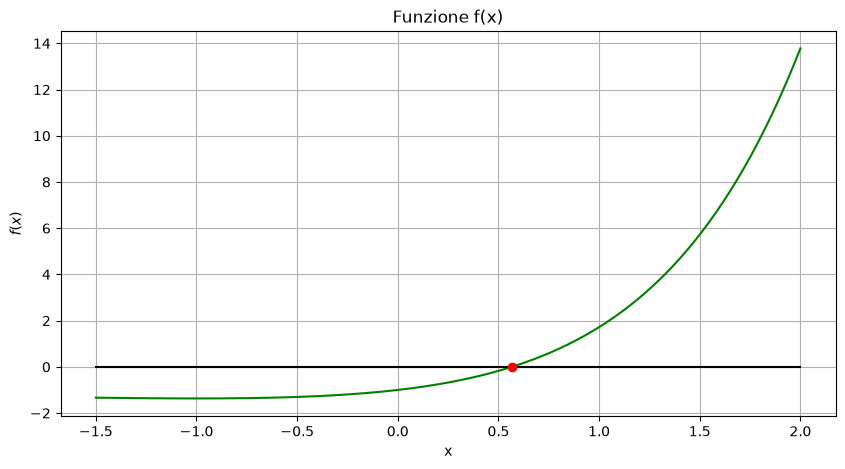

In [50]:
a = -1.5
b = 2

x = np.linspace(a, b, 200)
y = f(x)
yzeros = np.zeros_like(y)

plt.figure(figsize=(10, 5))
plt.plot(x,y, "-", color = 'green')
plt.plot(x,yzeros, "-", color = 'black')
plt.plot(x_star, f(x_star), "o", color = 'red')
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione f(x)")
plt.grid(True)

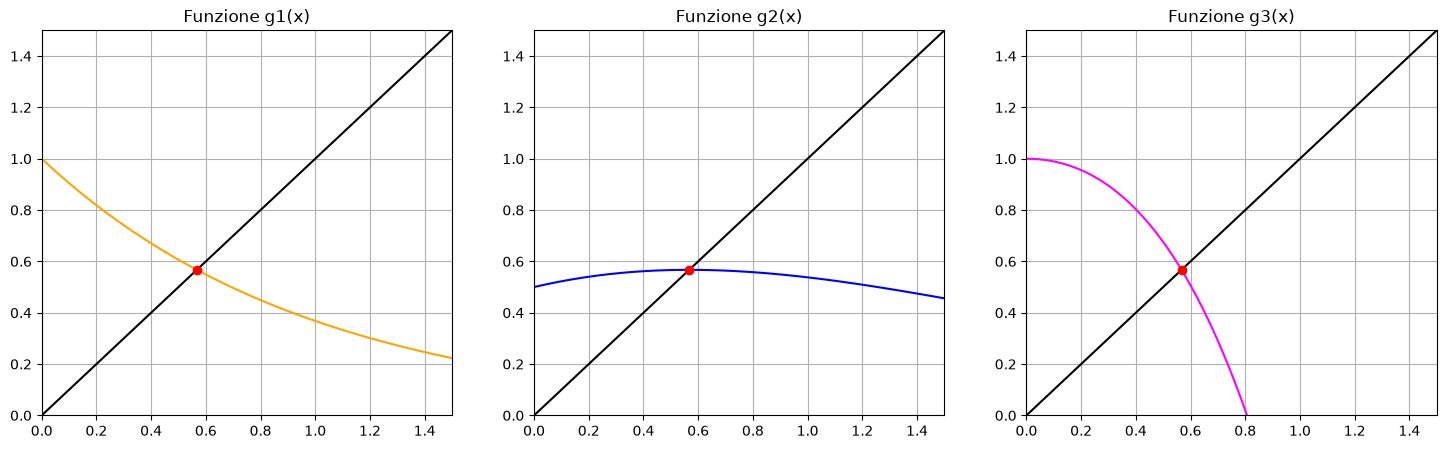

In [63]:
a1 = 0
b1 = 1.5

x1 = np.linspace(a1, b1, 200)
y1 = g1(x1)
y2 = g2(x1)
y3 = g3(x1)
yzeros1 = np.zeros_like(y1)

# Visualizzo
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(x1,y1, "-", color = 'orange')
plt.plot(x1,x1, "-", color = 'black')
plt.plot(x_star, g1(x_star), "o", color = 'red')
plt.xlim([a1, b1]), plt.ylim([a1, b1])
plt.title("Funzione g1(x)")
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(x1,y2, "-", color = 'blue')
plt.plot(x1,x1, "-", color = 'black')
plt.plot(x_star, g2(x_star), "o", color = 'red')
plt.xlim([a1, b1]), plt.ylim([a1, b1])
plt.title("Funzione g2(x)")
plt.grid()

plt.subplot(1, 3, 3)
plt.plot(x1,y3, "-", color = 'magenta')
plt.plot(x1,x1, "-", color = 'black')
plt.plot(x_star, g3(x_star), "o", color = 'red')
plt.title("Funzione g3(x)")
plt.xlim([a1, b1]), plt.ylim([a1, b1])
plt.grid()

plt.show()



#### Risoluzione 

In [52]:
def punto_fisso(g, x0, tol_x=1e-12, max_iter=100):

    x = x0
    iterati = [x]

    # Controllo del punto iniziale
    tol_f = tol_x
    if abs(g(x)-x0) <= tol_f:
        return x, 0, iterati

    for k in range(1, max_iter + 1):

        # Nuova approssimazione
        x_nuovo = g(x)
        iterati.append(x_nuovo)

        # Criterio di arresto
        if abs(x_nuovo - x) <= tol_x  + eps * min(abs(x_nuovo), abs(x)):
            print("Raggiunto il criterio di arresto.")
            return x_nuovo, k, iterati

        x = x_nuovo

    print("Raggiunto il numero massimo di iterazioni.")
    return x, max_iter, iterati

In [53]:
x0 = 5

x_sol1, n1, iterati1 = punto_fisso(g1, x0)
x_sol2, n2, iterati2 = punto_fisso(g2, x0)
x_sol3, n3, iterati3 = punto_fisso(g3, x0)

print("\nFunz. \t x_sol \t\t Iter. \t f(x_sol)")
print(f"g1 \t {x_sol1:.8f} \t {n1} \t {abs(f(x_sol1)):.3e}")
print(f"g2 \t {x_sol2:.8f} \t {n2} \t {abs(f(x_sol2)):.3e}")
print(f"g3 \t {x_sol3:.8f} \t {n3} \t {abs(f(x_sol3)):.3e}")


Raggiunto il criterio di arresto.
Raggiunto il criterio di arresto.
Raggiunto il numero massimo di iterazioni.

Funz. 	 x_sol 		 Iter. 	 f(x_sol)
g1 	 0.56714329 	 51 	 8.682e-13
g2 	 0.56714329 	 6 	 2.220e-16
g3 	 -637.06579551 	 100 	 1.000e+00


#### Calcolo derivate


In [ ]:
# TO DO - calcolo derivate

In [ ]:
# TO DO - valutazione derivate in x_star

#### Analisi errori

In [64]:
print("TABELLA ERRORI ASSOLUTO")
print("k \t  errore 1  \t errore 2 \t errore 3")
print("---------------------------------------------------------------")

iters = min(n1, n2, n3)
for k in range(1, iters+1): 
    errore_1 = np.abs(x_star - iterati1[k-1])
    errore_2 = np.abs(x_star - iterati2[k-1])
    errore_3 = np.abs(x_star - iterati3[k-1])
    
    print( f"{k} \t {errore_1:.10f}  \t {errore_2:.10f}  \t {errore_3:.10f} " )



TABELLA ERRORI ASSOLUTO
k 	  errore 1  	 errore 2 	 errore 3
---------------------------------------------------------------
1 	 4.4329000000  	 4.4329000000  	 4.4329000000 
2 	 0.5603620530  	 0.5269428945  	 736.6328955129 
3 	 0.4261847021  	 0.0574624688  	 735.6328955129 
4 	 0.1967418254  	 0.0005654910  	 734.6328955129 
5 	 0.1233869714  	 0.0000432233  	 733.6328955129 
6 	 0.0657681247  	 0.0000432904  	 732.6328955129 


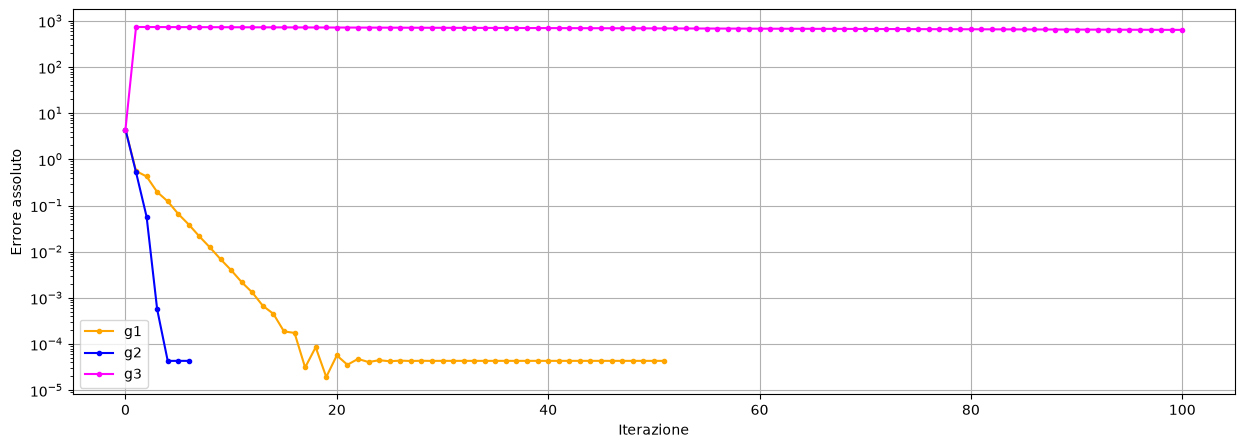

In [62]:
errori1 = np.abs(np.array(iterati1) - x_star)
errori2 = np.abs(np.array(iterati2) - x_star)
errori3 = np.abs(np.array(iterati3) - x_star)

plt.figure(figsize=(15, 5))

plt.semilogy(errori1, ".-", color="orange")
plt.semilogy(errori2, ".-", color="blue")
plt.semilogy(errori3, ".-", color="magenta")

plt.xlabel("Iterazione")
plt.ylabel("Errore assoluto")
plt.legend(["g1","g2","g3"])
plt.grid()
plt.show()